In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!mkdir -p /content/data
!unzip -q -n /content/drive/MyDrive/beam_data/scenario32.zip -d /content/data

In [11]:
!rm -rf /content/repo
!git clone -q https://github.com/nerminecheriaa/beam-prediction-deepsense6g.git /content/repo
import sys; sys.path.insert(0, "/content/repo")
from src.evaluate import topk_accuracy

In [4]:
import os, torch
from src.dataset import build_image_cache, get_split, IMG_SIZE
from src.evaluate import topk_accuracy

ROOT = "/content/data"
SPLITS = "/content/repo/splits.csv"
DRIVE_OUT = "/content/drive/MyDrive/beam_data/camera"
CACHE = f"{DRIVE_OUT}/cam_cache_224.pt"
os.makedirs(DRIVE_OUT, exist_ok=True)
print(torch.cuda.get_device_name(0))

Tesla T4


taille d’origine des images

In [5]:
from PIL import Image
import pandas as pd
df = pd.read_csv(SPLITS)
p0 = os.path.join(ROOT, df.unit1_rgb.iloc[0].replace("./", "", 1))
print(Image.open(p0).size)   # (largeur, hauteur)

(960, 540)


construction du cache

In [6]:
cache = build_image_cache(SPLITS, ROOT, CACHE)
print(cache["images"].shape, cache["images"].dtype)
for s in ["train", "val", "test"]:
    x, y, idx = get_split(cache, s)
    print(s, tuple(x.shape), "labels", y.min().item(), "->", y.max().item())

3235 images redimensionnées en 26.5 s
Cache sauvegardé : /content/drive/MyDrive/beam_data/camera/cam_cache_224.pt (487 Mo)
torch.Size([3235, 3, 224, 224]) torch.uint8
train (2265, 3, 224, 224) labels 1 -> 61
val (490, 3, 224, 224) labels 1 -> 61
test (480, 3, 224, 224) labels 1 -> 61


vérification visuelle

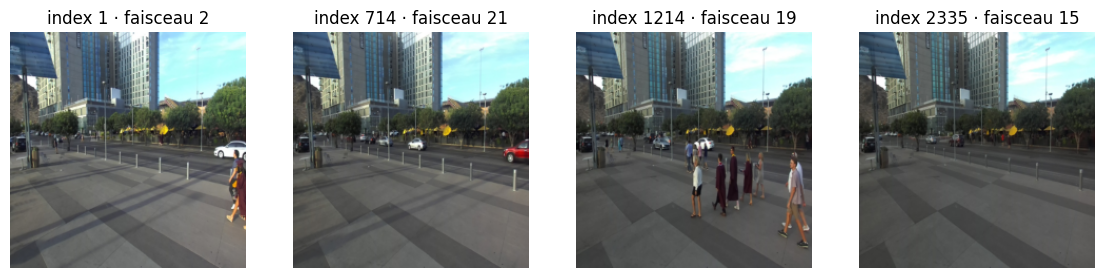

In [7]:
import matplotlib.pyplot as plt
x, y, idx = get_split(cache, "train")
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
for a, i in zip(ax, [0, 500, 1000, 2000]):
    a.imshow(x[i].permute(1, 2, 0).numpy()); a.set_title(f"index {idx[i].item()} · faisceau {y[i].item()}"); a.axis("off")
plt.show()

test du modèle

In [9]:
from src.models import CameraResNet18, count_params
from src.dataset import to_model_input, make_loader

device = "cuda"
model = CameraResNet18().to(device)
print("Paramètres entraînables :", f"{count_params(model):,}")

x_val, y_val, idx_val = get_split(cache, "val")
xb = to_model_input(x_val[:8], device)
with torch.no_grad():
    logits, feats = model(xb, return_features=True)
print("logits", tuple(logits.shape), "| features", tuple(feats.shape))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 130MB/s]


Paramètres entraînables : 11,209,344
logits (8, 64) | features (8, 512)


contrôle avant entraînement

In [10]:
model.eval(); all_logits = []
with torch.no_grad():
    for xb, yb in make_loader(x_val, y_val, batch_size=128):
        all_logits.append(model(to_model_input(xb, device)).cpu())
print("Val avant entraînement :", topk_accuracy(torch.cat(all_logits), y_val))

Val avant entraînement : {'top1': 0.01836734637618065, 'top3': 0.040816325694322586, 'top5': 0.06530611962080002}


entraînement

In [12]:
import importlib, src.train; importlib.reload(src.train)
from src.train import train_model, DEFAULT_CFG
print(DEFAULT_CFG)

x_tr, y_tr, idx_tr = get_split(cache, "train")
CKPT = f"{DRIVE_OUT}/camera_resnet18_best.pth"

model = CameraResNet18().to(device)
history = train_model(model, x_tr, y_tr, x_val, y_val, device, CKPT)

{'epochs': 20, 'batch_size': 64, 'lr': 0.0001, 'weight_decay': 0.0001, 'seed': 42}
ep  1 | train loss 3.318 top1 0.228 | val loss 3.881 top1 0.084 top3 0.194 top5 0.257 | 4.5s  <- meilleur (sauvegardé)
ep  2 | train loss 2.259 top1 0.400 | val loss 3.270 top1 0.176 top3 0.418 top5 0.539 | 3.6s  <- meilleur (sauvegardé)
ep  3 | train loss 1.742 top1 0.505 | val loss 3.204 top1 0.157 top3 0.373 top5 0.492 | 3.7s
ep  4 | train loss 1.426 top1 0.579 | val loss 2.971 top1 0.214 top3 0.473 top5 0.594 | 3.7s  <- meilleur (sauvegardé)
ep  5 | train loss 1.194 top1 0.633 | val loss 2.930 top1 0.259 top3 0.490 top5 0.588 | 3.7s  <- meilleur (sauvegardé)
ep  6 | train loss 1.010 top1 0.691 | val loss 2.977 top1 0.227 top3 0.455 top5 0.578 | 3.7s
ep  7 | train loss 0.805 top1 0.775 | val loss 2.861 top1 0.269 top3 0.500 top5 0.618 | 3.8s  <- meilleur (sauvegardé)
ep  8 | train loss 0.644 top1 0.832 | val loss 2.954 top1 0.280 top3 0.531 top5 0.618 | 3.9s  <- meilleur (sauvegardé)
ep  9 | train los

courbes d’apprentissage

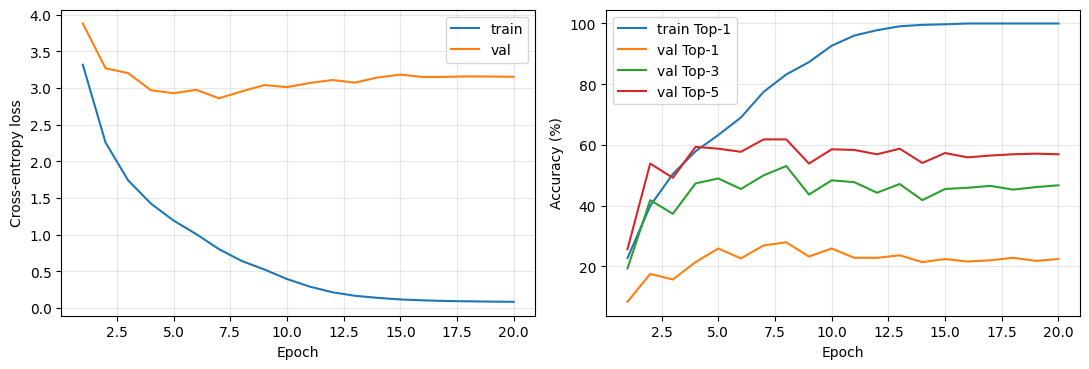

Meilleure époque : 8 {'val_top1': 0.28, 'val_top3': 0.531, 'val_top5': 0.618}


In [13]:
import pandas as pd, matplotlib.pyplot as plt
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)
for c, lab in [("train_top1", "train Top-1"), ("val_top1", "val Top-1"), ("val_top3", "val Top-3"), ("val_top5", "val Top-5")]:
    ax[1].plot(h.epoch, 100 * h[c], label=lab)
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig(f"{DRIVE_OUT}/camera_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()
best = h.loc[h.val_top1.idxmax()]
print("Meilleure époque :", int(best.epoch), best[["val_top1", "val_top3", "val_top5"]].round(3).to_dict())

recharger le meilleur modèle et l’évaluer

In [14]:
from src.train import predict
ckpt = torch.load(CKPT, weights_only=False)
model = CameraResNet18(pretrained=False).to(device)
model.load_state_dict(ckpt["model_state"])
print("Époque retenue :", ckpt["epoch"], "| val :", {k: round(100*v, 1) for k, v in ckpt["val"].items()})

x_tr, y_tr, idx_tr = get_split(cache, "train")
x_val, y_val, idx_val = get_split(cache, "val")
x_te, y_te, idx_te = get_split(cache, "test")

outs = {}
for s, (x, y, idx) in {"train": (x_tr, y_tr, idx_tr), "val": (x_val, y_val, idx_val), "test": (x_te, y_te, idx_te)}.items():
    lo, fe = predict(model, x, device, return_features=True)
    outs[s] = {"logits": lo, "features": fe, "labels": y, "index": idx}
    print(f"{s:5s} Camera CNN :", {k: round(100*v, 1) for k, v in topk_accuracy(lo, y).items()})

Époque retenue : 8 | val : {'top1': 28.0, 'top3': 53.1, 'top5': 61.8}
train Camera CNN : {'top1': 90.3, 'top3': 99.2, 'top5': 99.9}
val   Camera CNN : {'top1': 28.0, 'top3': 53.1, 'top5': 61.8}
test  Camera CNN : {'top1': 16.5, 'top3': 32.1, 'top5': 48.8}


baseline « faisceau le plus fréquent » sur val et test

In [15]:
counts = torch.bincount(y_tr, minlength=64).float()   # appris sur train uniquement
for s in ["val", "test"]:
    n = len(outs[s]["labels"])
    print(f"{s:5s} Fréquence  :", {k: round(100*v, 1) for k, v in topk_accuracy(counts.expand(n, 64), outs[s]["labels"]).items()})

val   Fréquence  : {'top1': 15.9, 'top3': 28.6, 'top5': 33.1}
test  Fréquence  : {'top1': 13.1, 'top3': 36.3, 'top5': 42.3}


sauvegarde (sur Drive)

In [16]:
torch.save({**outs, "best_epoch": ckpt["epoch"], "cfg": ckpt["cfg"],
            "info": "logits (N,64) et features (N,512) de CameraResNet18, triés par 'index' dans chaque split"},
           f"{DRIVE_OUT}/camera_outputs.pt")

top5 = outs["test"]["logits"].topk(5, dim=1).indices
pd.DataFrame({"index": idx_te.numpy(), "beam_label": y_te.numpy(),
              **{f"pred{k+1}": top5[:, k].numpy() for k in range(5)}}).to_csv(f"{DRIVE_OUT}/camera_test_predictions.csv", index=False)
print(os.listdir(DRIVE_OUT))

['cam_cache_224.pt', 'camera_resnet18_best.pth', 'camera_resnet18_best_history.json', 'camera_training_curves.png', 'camera_outputs.pt', 'camera_test_predictions.csv']


analyse des erreurs sur test

|faisceau prédit - vrai| <= 0 : 16.5 %
|faisceau prédit - vrai| <= 1 : 27.9 %
|faisceau prédit - vrai| <= 2 : 35.4 %
|faisceau prédit - vrai| <= 3 : 47.5 %
|faisceau prédit - vrai| <= 5 : 58.7 %


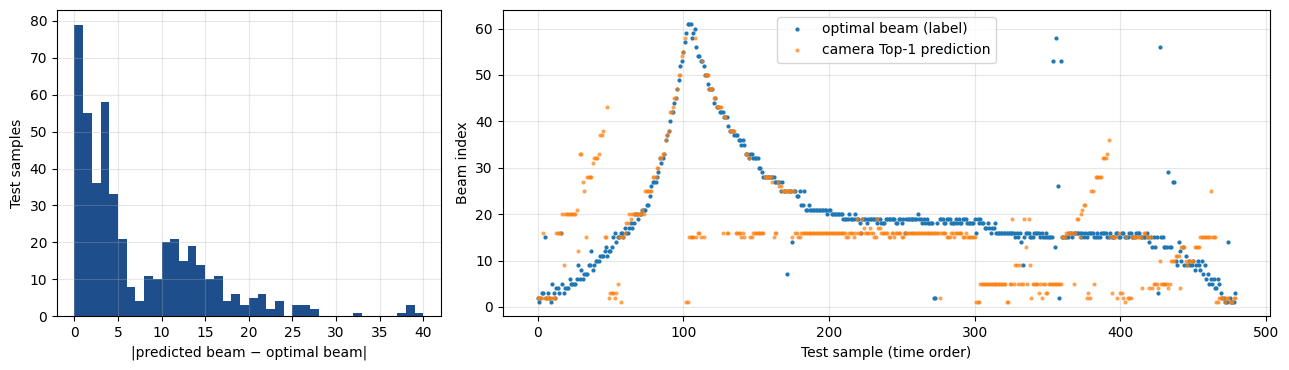

In [17]:
lo, y = outs["test"]["logits"], outs["test"]["labels"]
pred = lo.argmax(1); err = (pred - y).abs()
for d in [0, 1, 2, 3, 5]:
    print(f"|faisceau prédit - vrai| <= {d} : {100*(err <= d).float().mean().item():.1f} %")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 2]})
ax[0].hist(err.numpy(), bins=range(0, 41), color="#1f4e8c")
ax[0].set_xlabel("|predicted beam − optimal beam|"); ax[0].set_ylabel("Test samples"); ax[0].grid(alpha=.3)
ax[1].plot(y.numpy(), ".", ms=4, label="optimal beam (label)")
ax[1].plot(pred.numpy(), ".", ms=4, alpha=.6, label="camera Top-1 prediction")
ax[1].set_xlabel("Test sample (time order)"); ax[1].set_ylabel("Beam index"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{DRIVE_OUT}/camera_errors_test.png", dpi=200, bbox_inches="tight"); plt.show()